# Chapitre 7 - Cours 2 : isolation faible, read committed et snapshot isolation

Ce notebook couvre le début de la section *Weak Isolation Levels* : *Read Committed*
(*No dirty reads*, *No dirty writes*, *Implementing read committed*) et *Snapshot
Isolation and Repeatable Read* (*Implementing snapshot isolation*,
*Visibility rules for observing a consistent snapshot*, *Indexes and snapshot
isolation*, *Repeatable read and naming confusion*).
Les conflits entre écrivains (mises à jour perdues, write skew, fantômes) sont l'objet du
cours 3.

**Plan.**

1. Pourquoi des niveaux d'isolation « faibles » ? Les bogues de concurrence sont rares.
2. Read committed : pas de lecture sale.
3. Read committed : pas d'écriture sale.
4. Implémenter read committed : verrous d'écriture et deux versions.
5. Lecture biaisée (*read skew*) et instantanés.
6. MVCC : plusieurs versions de chaque ligne.
7. Les règles de visibilité.
8. Index, B-arbres immuables et ramasse-miettes.
9. Snapshot isolation, repeatable read : la confusion des noms.

Tous les scénarios sont rejoués sur le mini-moteur MVCC de
[`ddia/transactions.py`](../../ddia/transactions.py), qui implémente les niveaux
`read_uncommitted`, `read_committed`, `snapshot`, `serializable_ssi`,
`serializable_2pl` (et `none`, sans aucune protection).

In [1]:
import itertools

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import transactions as tr
from ddia.transactions import R, W, S, run, plot_history, Engine, LEVEL_LABELS
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## 1. Pourquoi des niveaux « faibles » ? (section *Weak Isolation Levels*)

Deux transactions qui ne touchent pas les mêmes données, ou qui ne font que lire, peuvent
s'exécuter en parallèle sans risque. Les conditions de course n'apparaissent que si l'une
lit ce que l'autre modifie, ou si les deux modifient la même chose. L'idéal est
l'**isolation sérialisable** : tout se passe comme si les transactions s'exécutaient une
par une. Mais elle a un coût, et beaucoup de bases utilisent par défaut des niveaux plus
faibles, qui protègent contre certaines anomalies seulement.

Le livre insiste sur un point : ces bogues sont **difficiles à trouver par les tests**,
parce qu'ils ne se déclenchent qu'avec un mauvais timing. Quantifions-le. Deux
transactions incrémentent un compteur (lecture, écriture, validation : 3 pas chacune). Il
y a $\binom{6}{3} = 20$ entrelacements possibles ; exécutons-les **tous** à chaque niveau.

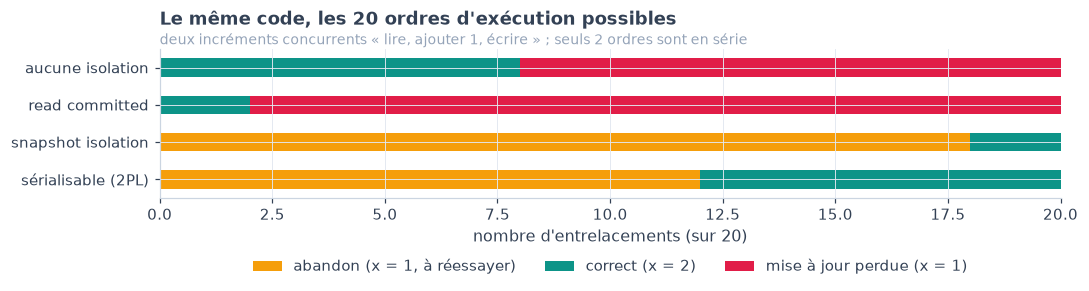

résultat,"abandon (x = 1, à réessayer)",correct (x = 2),mise à jour perdue (x = 1)
niveau,,,
aucune isolation,0,8,12
read committed,0,2,18
snapshot isolation,18,2,0
sérialisable (2PL),12,8,0


In [2]:
def incremente(cle):
    def prog():
        v = yield R(cle)
        yield W(cle, v + 1)
    return prog


def tous_les_entrelacements(n_a, n_b):
    for pos in itertools.combinations(range(n_a + n_b), n_a):
        yield ["A" if i in pos else "B" for i in range(n_a + n_b)]


niveaux = ["none", "read_committed", "snapshot", "serializable_2pl"]
lignes = []
for lvl in niveaux:
    for ordre in tous_les_entrelacements(3, 3):
        r = run({"x": 0}, {"A": incremente("x"), "B": incremente("x")}, ordre, level=lvl)
        lignes.append(dict(niveau=LEVEL_LABELS[lvl], ordre="".join(ordre),
                           résultat="correct (x = 2)" if r.final["x"] == 2 and not r.aborted else
                           ("abandon (x = 1, à réessayer)" if r.aborted else "mise à jour perdue (x = 1)")))
tab = pd.crosstab(pd.DataFrame(lignes)["niveau"], pd.DataFrame(lignes)["résultat"]).reindex(
    [LEVEL_LABELS[l] for l in niveaux])
ax = tab.plot.barh(stacked=True, figsize=(10, 3.6),
                   color={"correct (x = 2)": TEAL, "abandon (x = 1, à réessayer)": AMBER,
                    "mise à jour perdue (x = 1)": ROSE})
ax.invert_yaxis()
ax.set_xlabel("nombre d'entrelacements (sur 20)")
ax.set_ylabel("")
ax.set_title("Le même code, les 20 ordres d'exécution possibles")
subtitle(ax, "deux incréments concurrents « lire, ajouter 1, écrire » ; seuls 2 ordres sont en série")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.6), ncol=3)
plt.tight_layout(); plt.show()
tab

Sans protection, 12 entrelacements sur 20 perdent une mise à jour ; *read committed*
(le niveau par défaut de PostgreSQL, Oracle ou SQL Server) fait même pire, 18 sur 20,
car une transaction ne voit l'écriture de l'autre qu'après sa validation. Ce n'est pas
une anomalie que ce niveau prévient. La snapshot isolation de PostgreSQL et le
verrouillage à deux phases transforment les mauvais entrelacements en **abandons** que
l'application doit réessayer (18 et 12 sur 20) ; les cas restants sont corrects (seuls 2
ordres sont vraiment en série, mais d'autres leur sont équivalents).

Dans une vraie application, les transactions sont courtes et rarement simultanées : la
course ne se produit qu'**occasionnellement**, en production, sous charge, et de façon
presque impossible à reproduire.

Le livre rappelle que ces bogues ont coûté très cher (une plateforme d'échange de Bitcoin
mise en faillite, des données clients corrompues) et qu'un attaquant peut **provoquer**
délibérément la concurrence en envoyant des rafales de requêtes. « Utilisez une base
ACID » ne suffit pas : beaucoup de bases ACID tournent par défaut en isolation faible.

> **À retenir.** Une anomalie qui exige un timing malchanceux passe les tests et frappe
> en production. Il faut connaître précisément ce que chaque niveau d'isolation empêche.

## 2. Read committed : pas de lecture sale (section *No dirty reads*)

*Read committed* fait deux promesses : on ne lit que des données **validées** (pas de
lecture sale), et on n'écrase que des données validées (pas d'écriture sale).

Une **lecture sale** consiste à voir l'écriture d'une transaction qui n'a pas encore
validé. Deux raisons de l'interdire : un lecteur pourrait voir une partie des écritures
d'une transaction et pas le reste (cours 1, la messagerie), et il pourrait voir une donnée
qui sera **annulée**, donc qui n'aura jamais existé. Rejouons ce second cas : un
administrateur passe un prix de 20 € à 25 € puis se ravise (abandon) ; un client lit le
prix entre les deux.

 read uncommitted : le client lit 25 € ; prix final 20 €
   read committed : le client lit 20 € ; prix final 20 €


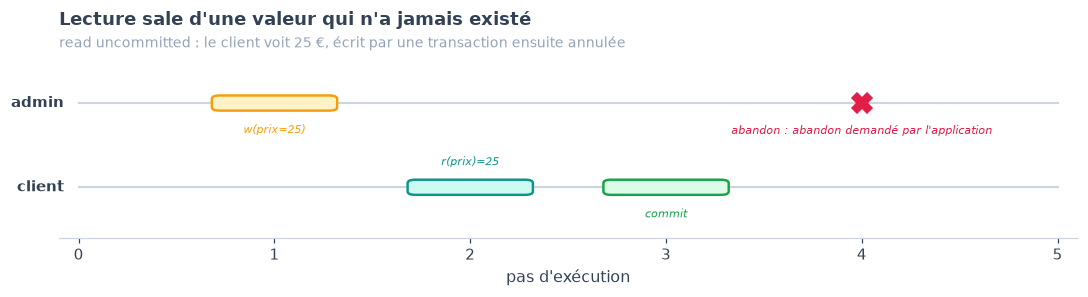

In [3]:
def modif_annulee():
    yield W("prix", 25)
    yield tr.ABORT


def client():
    p = yield R("prix")
    return p


for lvl in ["read_uncommitted", "read_committed"]:
    r = run({"prix": 20}, {"admin": modif_annulee, "client": client},
            ["admin", "client", "client", "admin"], level=lvl)
    print(f"{LEVEL_LABELS[lvl]:>17} : le client lit {r.reads['client'][0]} € ; prix final {r.final['prix']} €")
r = run({"prix": 20}, {"admin": modif_annulee, "client": client},
        ["admin", "client", "client", "admin"], level="read_uncommitted")
plot_history(r, title="Lecture sale d'une valeur qui n'a jamais existé",
             subtitle="read uncommitted : le client voit 25 €, écrit par une transaction ensuite annulée",
             width=10).show()

Sous *read uncommitted*, le client a vu 25 €, un prix qui n'a jamais été validé. Si le
client avait écrit quelque chose à partir de cette lecture, il faudrait aussi l'annuler :
c'est l'**abandon en cascade**. Sous *read committed*, il lit 20 €.

> **À retenir.** Pas de lecture sale = les écritures d'une transaction deviennent visibles
> toutes ensemble, au moment de sa validation, et jamais si elle est annulée.

## 3. Read committed : pas d'écriture sale (section *No dirty writes*)

Une **écriture sale** écrase une valeur écrite par une transaction **non encore
validée**. Le livre prend deux acheteurs d'une même voiture ; prenons deux spectateurs
qui réservent le même siège de concert. Réserver = deux écritures : attribuer le siège,
puis émettre le billet. Sans protection, le siège peut revenir à l'un et le billet à
l'autre.

 aucune isolation : siège -> Basile, billet -> Alma
   read committed : siège -> Basile, billet -> Basile


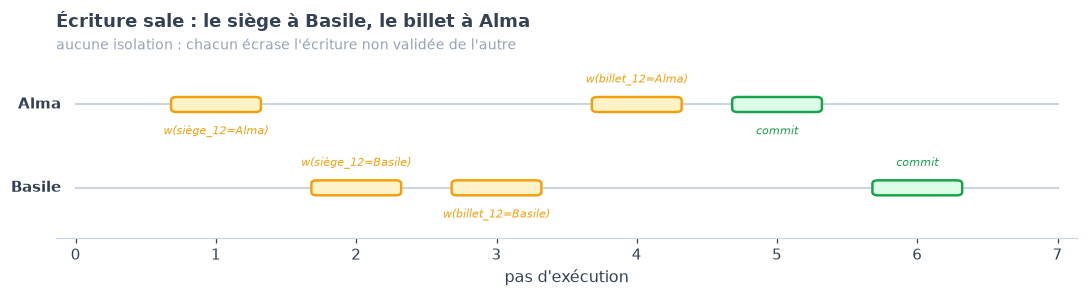

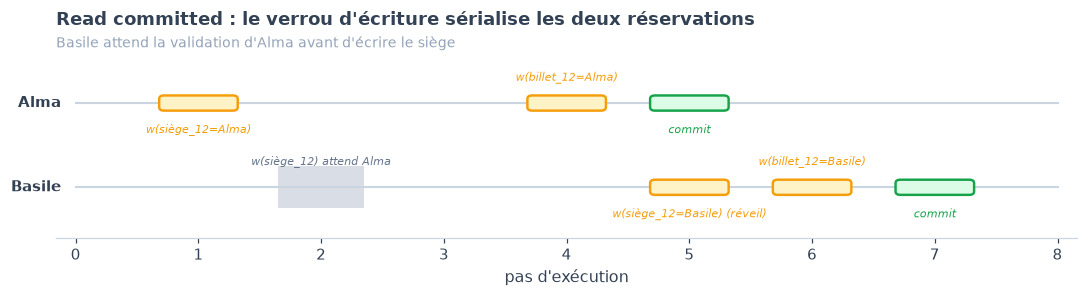

In [4]:
def reserve(qui):
    def prog():
        yield W("siège_12", qui)
        yield W("billet_12", qui)
    return prog


ordre = ["Alma", "Basile", "Basile", "Alma", "Alma", "Basile"]
fig_res = {}
for lvl in ["none", "read_committed"]:
    r = run({"siège_12": None, "billet_12": None}, {"Alma": reserve("Alma"), "Basile": reserve("Basile")},
            ordre, level=lvl)
    fig_res[lvl] = r
    print(f"{LEVEL_LABELS[lvl]:>17} : siège -> {r.final['siège_12']}, billet -> {r.final['billet_12']}")
plot_history(fig_res["none"], title="Écriture sale : le siège à Basile, le billet à Alma",
             subtitle="aucune isolation : chacun écrase l'écriture non validée de l'autre", width=10).show()
plot_history(fig_res["read_committed"], title="Read committed : le verrou d'écriture sérialise les deux réservations",
             subtitle="Basile attend la validation d'Alma avant d'écrire le siège", width=10).show()

Sans verrou, le siège revient à Basile (dernier à l'écrire) et le billet à Alma : un
état qu'aucune exécution en série ne produit. Sous *read committed*, Basile attend que la
transaction d'Alma se termine : les deux réservations s'appliquent en bloc, la seconde
écrasant entièrement la première (l'application doit encore vérifier que le siège est
libre, mais au moins l'état est cohérent).

Attention, *read committed* n'empêche **pas** la mise à jour perdue de la section 1 : la
seconde écriture y arrive **après** la validation de la première ; ce n'est pas une
écriture sale, mais elle est fausse pour une autre raison (cours 3).

> **À retenir.** Pas d'écriture sale = un verrou exclusif par ligne écrite, tenu jusqu'à
> la fin de la transaction. C'est la protection minimale de presque toutes les bases.

## 4. Implémenter read committed (section *Implementing read committed*)

- **Écritures** : verrou exclusif par ligne, acquis à la première écriture et rendu à la
  validation ou à l'abandon.
- **Lectures** : on pourrait exiger un verrou de lecture bref sur la ligne (le lecteur
  attendrait la fin de l'écrivain). Mais une longue transaction d'écriture bloquerait
  alors tous les lecteurs, et un ralentissement dans une partie de l'application se
  propagerait ailleurs. La plupart des bases retiennent donc **deux versions** de chaque
  ligne en cours de modification : l'ancienne valeur validée, donnée aux lecteurs, et la
  nouvelle, visible seulement de son écrivain.

Mesurons la différence. Une transaction d'écriture modifie la ligne `x` puis travaille
encore 12 pas avant de valider ; pendant ce temps, six lecteurs arrivent et lisent `x`.
Le niveau `serializable_2pl` du moteur prend des verrous de lecture : il sert ici de
modèle de l'approche « verrous de lecture ».

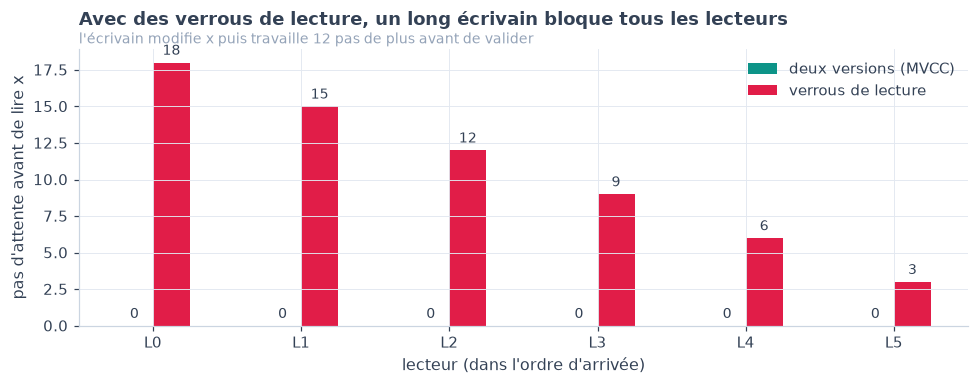

In [5]:
def long_ecrivain():
    yield W("x", 1)
    for i in range(12):
        yield R(f"autre{i}")


def lecteur():
    yield R("x")


def attentes(level):
    progs = {"écrivain": long_ecrivain}
    progs.update({f"L{i}": lecteur for i in range(6)})
    ordre = ["écrivain"] + [n for i in range(6) for n in (f"L{i}", "écrivain", "écrivain")]
    r = run({"x": 0, **{f"autre{i}": 0 for i in range(12)}}, progs, ordre, level=level)
    h = r.history
    out = {}
    for i in range(6):
        e = h[h["tx"] == f"L{i}"]
        debut = e["pas"].min()
        fin = e[(e["type"] == "read") & e["op"].str.startswith("r(x)")]["pas"].min()
        out[f"L{i}"] = fin - debut
    return out, r


att_mvcc, _ = attentes("read_committed")
att_verrous, r_verrous = attentes("serializable_2pl")
df = pd.DataFrame({"deux versions (MVCC)": att_mvcc, "verrous de lecture": att_verrous})
ax = df.plot.bar(figsize=(9, 3.6), color=[TEAL, ROSE], rot=0)
annotate_bars(ax, "{:.0f}")
ax.set_xlabel("lecteur (dans l'ordre d'arrivée)")
ax.set_ylabel("pas d'attente avant de lire x")
ax.set_title("Avec des verrous de lecture, un long écrivain bloque tous les lecteurs")
subtitle(ax, "l'écrivain modifie x puis travaille 12 pas de plus avant de valider")
plt.tight_layout(); plt.show()

Avec deux versions, aucun lecteur n'attend : ils lisent l'ancienne valeur validée
(`x = 0`). Avec des verrous de lecture, chaque lecteur attend jusqu'à la validation de
l'écrivain : le premier arrivé attend le plus longtemps. Quelques bases utilisent
pourtant des verrous pour éviter les lectures sales (IBM Db2, SQL Server avec
`read_committed_snapshot=off`).

**Read uncommitted**, encore plus faible, empêche les écritures sales mais pas les
lectures sales : il renvoie la dernière valeur écrite, validée ou non, ce qui économise la
seconde version.

> **À retenir.** Read committed = verrous exclusifs pour les écritures + ancienne version
> validée pour les lecteurs. Les lecteurs ne bloquent pas, et ne sont pas bloqués.

## 5. Lecture biaisée et instantanés (section *Snapshot Isolation and Repeatable Read*)

*Read committed* laisse passer une anomalie subtile. Inès a 1 000 € répartis sur deux
comptes de 500 €. Un virement de 100 € du compte 2 vers le compte 1 s'exécute pendant
qu'elle consulte ses soldes : elle lit le compte 1 **avant** le crédit (500 €) et le
compte 2 **après** le débit (400 €). Il manque 100 € !

    read committed : Inès voit 500 € + 400 € = 900 €
snapshot isolation : Inès voit 500 € + 500 € = 1000 €


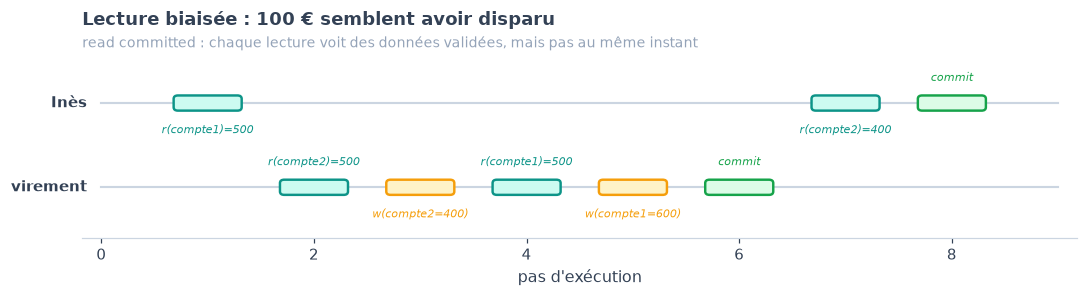

In [6]:
def virement():
    b = yield R("compte2")
    yield W("compte2", b - 100)
    a = yield R("compte1")
    yield W("compte1", a + 100)


def consultation():
    a = yield R("compte1")
    b = yield R("compte2")
    return a, b


init = {"compte1": 500, "compte2": 500}
ordre = ["Inès", "virement", "virement", "virement", "virement", "virement", "Inès", "Inès"]
for lvl in ["read_committed", "snapshot"]:
    r = run(init, {"Inès": consultation, "virement": virement}, ordre, level=lvl)
    a, b = r.reads["Inès"]
    print(f"{LEVEL_LABELS[lvl]:>18} : Inès voit {a} € + {b} € = {a + b} €")
r = run(init, {"Inès": consultation, "virement": virement}, ordre, level="read_committed")
plot_history(r, title="Lecture biaisée : 100 € semblent avoir disparu",
             subtitle="read committed : chaque lecture voit des données validées, mais pas au même instant",
             width=10).show()

Chaque valeur lue était bien validée au moment de sa lecture : *read committed* est
respecté. C'est une **lecture biaisée** (*read skew*), aussi appelée **lecture non
répétable** : relire le compte 1 donnerait 600 €. Pour Inès, rafraîchir la page suffit.
Mais deux usages ne tolèrent pas cette incohérence temporaire :

- les **sauvegardes**, qui copient la base pendant des heures alors que les écritures
  continuent : l'incohérence devient permanente si l'on restaure ;
- les **requêtes analytiques** et les **contrôles d'intégrité**, qui parcourent une grande
  partie de la base.

Simulons une sauvegarde de 20 comptes de 100 € (une ligne copiée par pas) pendant que des
virements aléatoires s'exécutent, et regardons le total sauvegardé sur 300 essais.

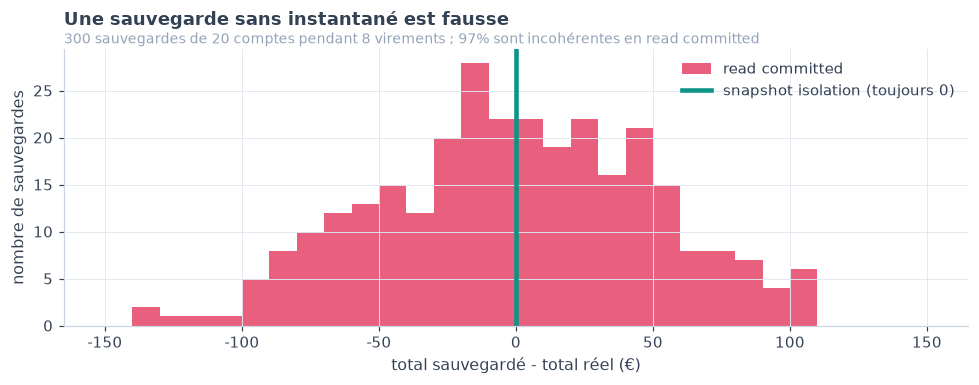

,read committed,snapshot isolation
mean,-1.010,0.0
std,51.906,0.0
min,-177.000,0.0
max,161.000,0.0


In [7]:
def sauvegarde(n):
    def prog():
        total = 0
        for i in range(n):
            total += yield R(f"c{i}")
        return total
    return prog


def virement_aleatoire(src, dst, montant):
    def prog():
        a = yield R(src)
        yield W(src, a - montant)
        b = yield R(dst)
        yield W(dst, b + montant)
    return prog


def essai_sauvegarde(level, seed, n=20, n_vir=8):
    g = np.random.default_rng(seed)
    progs = {"backup": sauvegarde(n)}
    for k in range(n_vir):
        s, d = g.choice(n, 2, replace=False)
        progs[f"v{k}"] = virement_aleatoire(f"c{s}", f"c{d}", int(g.integers(1, 50)))
    ordre = []
    for k in range(n_vir):
        ordre += ["backup", "backup"] + [f"v{k}"] * 5
    r = run({f"c{i}": 100 for i in range(n)}, progs, ordre + ["backup"] * (n + 1), level=level)
    return sum(r.reads["backup"]) - 100 * n

erreurs = pd.DataFrame({LEVEL_LABELS[l]: [essai_sauvegarde(l, s) for s in range(300)]
                        for l in ["read_committed", "snapshot"]})
fig, ax = plt.subplots(figsize=(9, 3.6))
bins = np.arange(-150, 151, 10)
ax.hist(erreurs[LEVEL_LABELS["read_committed"]], bins=bins, color=ROSE, alpha=0.7, label="read committed")
ax.axvline(0, color=TEAL, lw=3, label="snapshot isolation (toujours 0)")
ax.set_xlabel("total sauvegardé - total réel (€)")
ax.set_ylabel("nombre de sauvegardes")
ax.set_title("Une sauvegarde sans instantané est fausse")
frac = (erreurs[LEVEL_LABELS["read_committed"]] != 0).mean()
subtitle(ax, f"300 sauvegardes de 20 comptes pendant 8 virements ; {frac:.0%} sont incohérentes en read committed")
ax.legend()
plt.tight_layout(); plt.show()
erreurs.describe().loc[["mean", "std", "min", "max"]]

En *read committed*, la grande majorité des sauvegardes sont fausses (de l'argent créé ou
détruit selon que la copie a croisé un virement d'un côté ou de l'autre). En **snapshot
isolation**, chaque transaction lit un **instantané cohérent** : tout ce qui était validé
à son début, et rien d'autre, même si les données changent ensuite. L'écart est toujours
nul. C'est le niveau idéal pour les longues lectures (sauvegardes, analytique) ; il est
proposé, avec des variantes, par PostgreSQL, MySQL/InnoDB, Oracle ou SQL Server.

> **À retenir.** Snapshot isolation : chaque transaction lit la base telle qu'elle était
> à son début. Elle supprime la lecture biaisée, indispensable aux sauvegardes et aux
> requêtes longues.

## 6. MVCC : plusieurs versions de chaque ligne (section *Implementing snapshot isolation*)

Comme *read committed*, la snapshot isolation utilise des verrous d'écriture (pas
d'écriture sale) mais **aucun verrou de lecture** : « les lecteurs ne bloquent jamais les
écrivains, et les écrivains ne bloquent jamais les lecteurs ». Il faut alors garder
**plusieurs versions validées** de chaque ligne, car des transactions en cours peuvent
avoir besoin d'états différents : c'est le **contrôle de concurrence multiversion**
(*MVCC*).

À la manière de PostgreSQL, chaque transaction reçoit un identifiant croissant (`txid`)
et chaque version de ligne porte deux champs : `created_by` (`xmin` dans PostgreSQL),
l'identifiant de la transaction qui l'a créée, et `deleted_by` (`xmax`), celui de la
transaction qui l'a supprimée. Une mise à jour est une suppression suivie d'une
insertion. Reconstituons un scénario : la transaction 1 crée deux comptes, la
transaction 2 (Inès) commence à lire, la transaction 3 vire 100 € du compte 2 vers le
compte 1 et valide, puis Inès termine sa lecture.

In [8]:
eng = Engine({}, level="snapshot")
t1 = eng.begin("création")
eng.write(t1, "compte1", 500); eng.write(t1, "compte2", 500); eng.commit(t1)
t2 = eng.begin("Inès")
lu1 = eng.read(t2, "compte1")
t3 = eng.begin("virement")
eng.write(t3, "compte2", eng.read(t3, "compte2") - 100)
eng.write(t3, "compte1", eng.read(t3, "compte1") + 100)
eng.commit(t3)
lu2 = eng.read(t2, "compte2")
print(f"Inès (txid {t2.txid}) lit compte1 = {lu1} et compte2 = {lu2} : total {lu1 + lu2}")
eng.versions_table()

Inès (txid 2) lit compte1 = 500 et compte2 = 500 : total 1000


,clé,valeur,created_by,deleted_by,statut_créateur
0,compte1,500,1,3,committed
1,compte1,600,3,,committed
2,compte2,500,1,3,committed
3,compte2,400,3,,committed


Chaque compte a maintenant deux versions physiques. Celle à 500 € du compte 2 est marquée
`deleted_by = 3`, et une nouvelle version à 400 € a `created_by = 3`. Inès (txid 2) a
commencé **avant** la validation de la transaction 3 : elle ignore ses écritures et voit
1 000 €. Le schéma montre la chaîne de versions du compte 2.

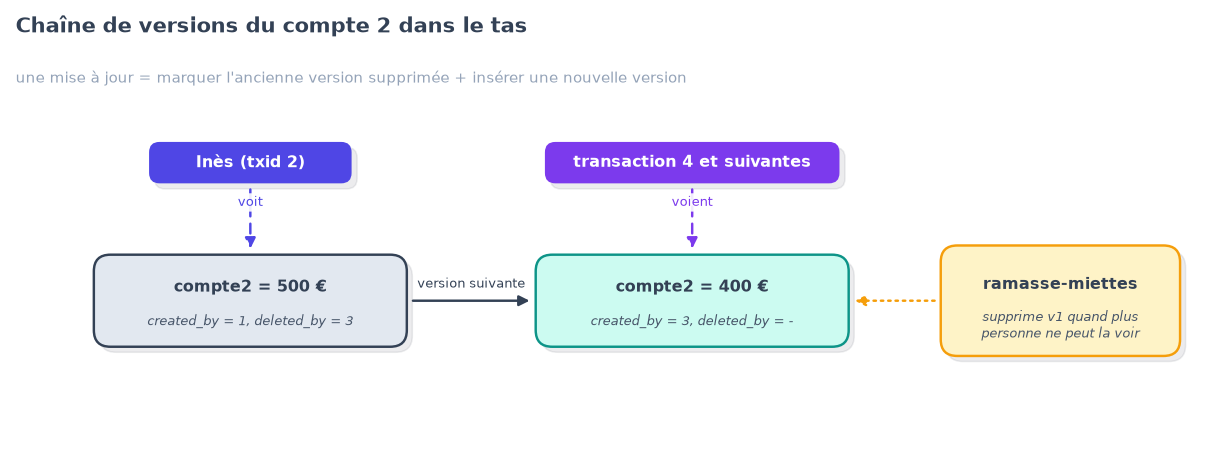

In [9]:
d = Diagram(13, 3.8, title="Chaîne de versions du compte 2 dans le tas",
            subtitle="une mise à jour = marquer l'ancienne version supprimée + insérer une nouvelle version")
d.box("v1", 2.6, 1.6, "compte2 = 500 €", sub="created_by = 1, deleted_by = 3", color=SLATE, w=3.4, h=1.0)
d.box("v2", 7.4, 1.6, "compte2 = 400 €", sub="created_by = 3, deleted_by = -", color=TEAL, w=3.4, h=1.0)
d.arrow("v1", "v2", "version suivante")
d.box("t2", 2.6, 3.1, "Inès (txid 2)", color=INDIGO, kind="tag", w=2.2, h=0.45)
d.box("t4", 7.4, 3.1, "transaction 4 et suivantes", color=VIOLET, kind="tag", w=3.2, h=0.45)
d.arrow("t2", "v1", "voit", color=INDIGO, style="dashed")
d.arrow("t4", "v2", "voient", color=VIOLET, style="dashed")
d.box("gc", 11.4, 1.6, "ramasse-miettes", sub="supprime v1 quand plus\npersonne ne peut la voir", color=AMBER, w=2.6, h=1.2)
d.arrow("gc", "v2", style="dotted", color=AMBER)
d.show()

Toutes les versions vivent dans le même tas, validées ou non, chaînées de la plus récente
à la plus ancienne (ou l'inverse). Une transaction annulée n'a pas besoin d'être
nettoyée immédiatement : ses versions sont simplement invisibles (règle 3 ci-dessous) et
le ramasse-miettes les supprimera.

> **À retenir.** MVCC = ne jamais écraser en place : chaque écriture crée une version
> étiquetée par l'identifiant de son écrivain ; chaque lecture choisit la version qui lui
> est visible.

## 7. Les règles de visibilité (section *Visibility rules for observing a consistent snapshot*)

Au début d'une transaction $T$, la base note la liste des transactions **en cours**. Puis,
pour chaque version, elle ignore les écritures :

1. des transactions en cours au début de $T$ (même si elles valident ensuite) ;
2. des transactions d'identifiant supérieur (commencées après $T$) ;
3. des transactions annulées ;

et voit toutes les autres. Autrement dit, une version est visible si son créateur avait
**validé avant le début** de $T$, et si elle n'a pas été supprimée par une transaction
**validée avant le début** de $T$. Dans le moteur, c'est la méthode `Engine._sees` (avec
`snap_active` la liste des transactions en cours et `snap_xmax` le prochain
identifiant). Construisons une petite histoire et calculons, pour chaque transaction de
lecture, la version de `x` qu'elle voit.

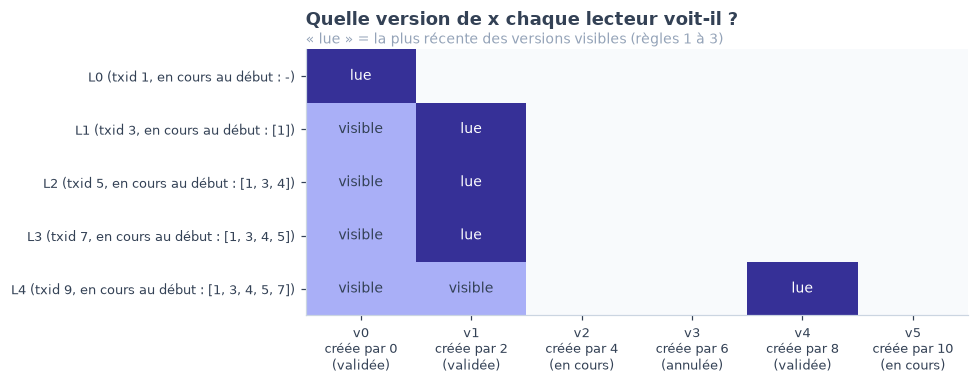

In [10]:
eng = Engine({"x": "v0"}, level="snapshot")
lecteurs = {}
# les écrivains n'utilisent pas de verrou (niveau "none") pour pouvoir coexister sur x
for k in range(5):
    lecteurs[f"L{k}"] = eng.begin(f"L{k}")
    e = eng.begin(f"E{k}", level="none")
    eng.write(e, "x", f"v{k + 1}")
    if k in (0, 3):
        eng.commit(e)        # E0 et E3 valident
    elif k == 2:
        eng.abort(e)         # E2 est annulée ; E1 et E4 restent en cours
versions = [v for v in eng.versions["x"]]
mat = np.zeros((len(lecteurs), len(versions)))
for i, t in enumerate(lecteurs.values()):
    vis = eng._visible(t, "x")
    for j, v in enumerate(versions):
        mat[i, j] = 2 if v is vis else (1 if eng._sees(t, v.xmin) else 0)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.imshow(mat, cmap="ddia_seq", vmin=0, vmax=2.4, aspect="auto")
statut = {tid: eng.status[tid] for tid in eng.status}
ax.set_xticks(range(len(versions)))
ax.set_xticklabels([f"{v.value}\ncréée par {v.xmin}\n({ {'committed': 'validée', 'aborted': 'annulée', 'active': 'en cours'}[statut[v.xmin]] })"
                    for v in versions], fontsize=8.5)
ax.set_yticks(range(len(lecteurs)))
ax.set_yticklabels([f"{n} (txid {t.txid}, en cours au début : {sorted(t.snap_active) or '-'})"
                    for n, t in lecteurs.items()], fontsize=8.5)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        ax.text(j, i, {2: "lue", 1: "visible", 0: ""}[mat[i, j]], ha="center", va="center",
                color="white" if mat[i, j] == 2 else SLATE, fontsize=9)
ax.grid(False)
ax.set_title("Quelle version de x chaque lecteur voit-il ?")
subtitle(ax, "« lue » = la plus récente des versions visibles (règles 1 à 3)")
plt.tight_layout(); plt.show()

Lecture du tableau : `L0` (txid 1) a commencé avant toute écriture : il ne voit que `v0`.
`L1` (txid 3) voit `v1`, validée par la transaction 2 avant son début. `L2` (txid 5)
ignore `v2` (transaction 4, encore en cours à son début, règle 1) et voit `v1`.
Personne ne voit `v3` (transaction 6 annulée, règle 3). `L4` (txid 9) voit `v4`, validée
par la transaction 8 avant son début ; `v5` est encore en cours (règle 1). Les lecteurs
`L0` à `L3` ne voient pas `v4` (règle 2 : créateur commencé après eux) ; `L3` (txid 7)
voit donc encore `v1`.

> **À retenir.** Une version est visible si son créateur a validé **avant le début** du
> lecteur. Ces règles suffisent à présenter à chaque transaction un instantané figé, sans
> aucun verrou de lecture.

## 8. Index, B-arbres immuables et ramasse-miettes (section *Indexes and snapshot isolation*)

**Index.** Le plus souvent, chaque entrée d'index pointe vers une version de la ligne,
et la requête parcourt la chaîne de versions pour trouver celle qui est visible.
PostgreSQL évite même de toucher l'index quand la nouvelle version tient dans la même
page. D'autres bases ne stockent que les différences entre versions.

**Ramasse-miettes.** Une version ne peut être supprimée que lorsque **plus aucune**
transaction ne peut la voir. Une transaction très longue retient donc toutes les
versions créées depuis son début. Simulons 200 mises à jour d'une même ligne, avec un
passage du ramasse-miettes (`Engine.vacuum`) tous les 10 pas, avec et sans une longue
transaction de lecture ouverte entre les pas 50 et 150.

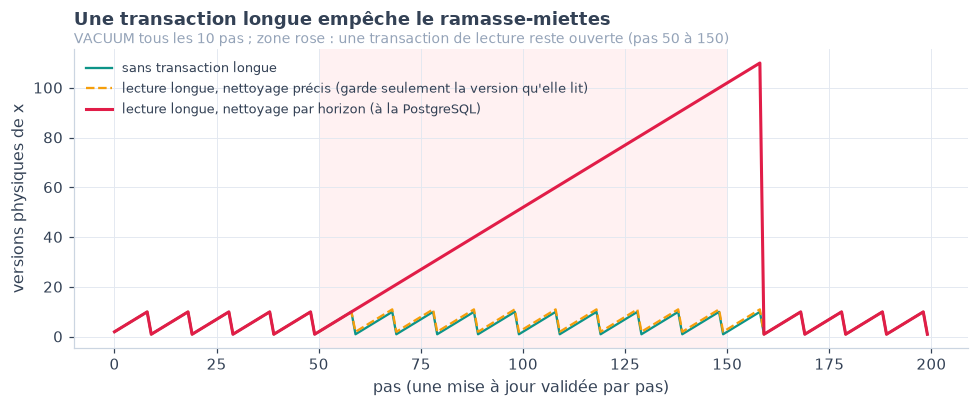

In [11]:
def versions_dans_le_temps(lecteur_long, horizon=False):
    eng = Engine({"x": 0}, level="snapshot")
    long_tx = None
    hist = []
    for t in range(200):
        if lecteur_long and t == 50:
            long_tx = eng.begin("longue")
            eng.read(long_tx, "x")
        if long_tx is not None and t == 150:
            eng.commit(long_tx)
            long_tx = None
        w = eng.begin()
        eng.write(w, "x", t)
        eng.commit(w)
        if t % 10 == 9:
            eng.vacuum(horizon=horizon)
        hist.append(len(eng.versions["x"]))
    return hist

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(versions_dans_le_temps(False), color=TEAL, lw=1.5, label="sans transaction longue")
ax.plot(versions_dans_le_temps(True, horizon=False), color=AMBER, lw=1.5, ls="--",
        label="lecture longue, nettoyage précis (garde seulement la version qu'elle lit)")
ax.plot(versions_dans_le_temps(True, horizon=True), color=ROSE,
        label="lecture longue, nettoyage par horizon (à la PostgreSQL)")
ax.axvspan(50, 150, color=LIGHT[ROSE], alpha=0.5, lw=0)
ax.set_xlabel("pas (une mise à jour validée par pas)")
ax.set_ylabel("versions physiques de x")
ax.set_title("Une transaction longue empêche le ramasse-miettes")
subtitle(ax, "VACUUM tous les 10 pas ; zone rose : une transaction de lecture reste ouverte (pas 50 à 150)")
ax.legend(loc="upper left", fontsize=8.5)
plt.tight_layout(); plt.show()

Sans transaction longue, le ramasse-miettes ramène régulièrement la ligne à une version
(dents de scie). Avec une lecture longue, tout dépend de la finesse du nettoyage. Un
nettoyage **précis** ne garde que la version lue par la transaction longue (une de plus).
Mais PostgreSQL raisonne par **horizon** : il ne supprime une version que si une version
plus récente est visible de toutes les transactions actives, donc rien de ce qui a été
écrit depuis le début de la plus vieille transaction. La ligne accumule alors une
centaine de versions jusqu'à la fin de la lecture, puis tout est nettoyé d'un coup. C'est
un problème opérationnel classique : une transaction oubliée ouverte fait gonfler les
tables et ralentit toutes les lectures (chaînes de versions plus longues).

**B-arbres immuables.** CouchDB, Datomic ou LMDB utilisent une autre approche : un
B-arbre en **copie sur écriture**. Modifier une feuille crée une copie de la feuille et de
tous ses ancêtres jusqu'à une **nouvelle racine** ; les pages non modifiées sont
partagées. Chaque racine est un instantané cohérent, sans aucun filtrage par
identifiant de transaction (mais il faut un compactage en arrière-plan).

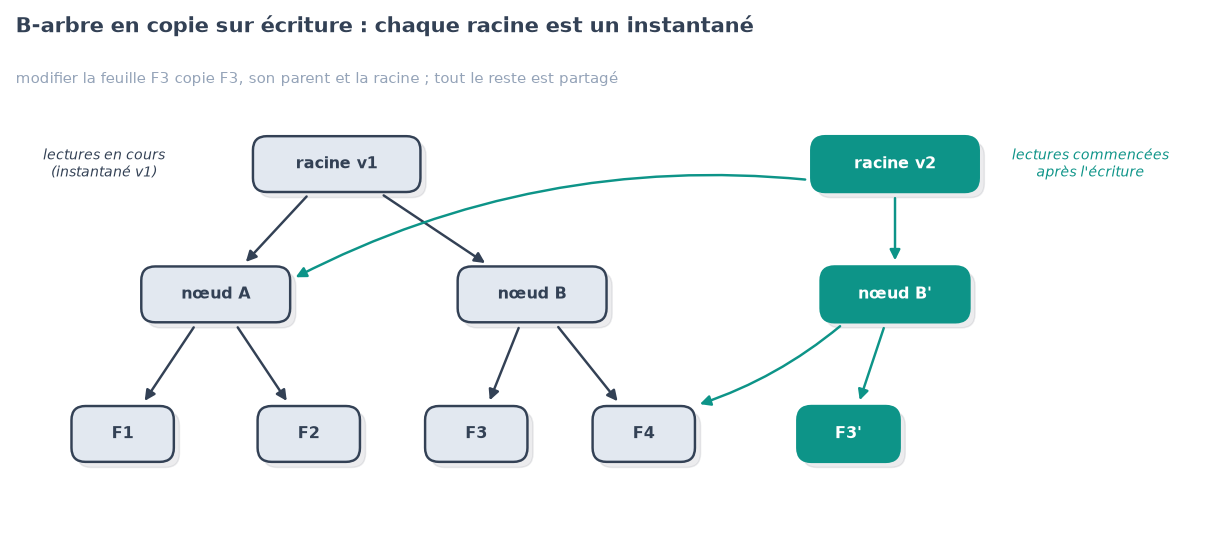

In [12]:
d = Diagram(13, 4.6, title="B-arbre en copie sur écriture : chaque racine est un instantané",
            subtitle="modifier la feuille F3 copie F3, son parent et la racine ; tout le reste est partagé")
d.box("r1", 3.5, 3.9, "racine v1", color=SLATE, w=1.8, h=0.6)
d.box("r2", 9.5, 3.9, "racine v2", color=TEAL, w=1.8, h=0.6, filled=True)
d.box("a", 2.2, 2.5, "nœud A", color=SLATE, w=1.6, h=0.6)
d.box("b", 5.6, 2.5, "nœud B", color=SLATE, w=1.6, h=0.6)
d.box("b2", 9.5, 2.5, "nœud B'", color=TEAL, w=1.6, h=0.6, filled=True)
for name, x, txt in [("f1", 1.2, "F1"), ("f2", 3.2, "F2"), ("f3", 5.0, "F3"), ("f4", 6.8, "F4")]:
    d.box(name, x, 1.0, txt, color=SLATE, w=1.1, h=0.6)
d.box("f3b", 9.0, 1.0, "F3'", color=TEAL, w=1.1, h=0.6, filled=True)
for a, b in [("r1", "a"), ("r1", "b"), ("a", "f1"), ("a", "f2"), ("b", "f3"), ("b", "f4")]:
    d.arrow(a, b, color=SLATE)
d.arrow("r2", "a", color=TEAL, rad=0.15)
d.arrow("r2", "b2", color=TEAL)
d.arrow("b2", "f3b", color=TEAL)
d.arrow("b2", "f4", color=TEAL, rad=-0.1)
d.note(11.6, 3.9, "lectures commencées\naprès l'écriture", color=TEAL)
d.note(1.0, 3.9, "lectures en cours\n(instantané v1)", color=SLATE)
d.show()

> **À retenir.** MVCC déplace le coût de la concurrence vers le stockage : versions
> multiples, chaînes à parcourir, ramasse-miettes. Les transactions longues sont
> l'ennemi du nettoyage.